## Introduction to Linear Regression


Dataset:
   Hours  Score
0      1     42
1      2     49
2      3     61
3      4     73
4      5     79

Model Coefficients:
Intercept (b0): 31.400
Slope (b1): 9.800

Evaluation Metrics:
MAE  = 1.360
MSE  = 2.480
RMSE = 1.575
R²   = 0.987
Adj R² = 0.983

Prediction Results:
   Hours  Actual_Score  Predicted_Score  Residual
0      1            42             41.2       0.8
1      2            49             51.0      -2.0
2      3            61             60.8       0.2
3      4            73             70.6       2.4
4      5            79             80.4      -1.4


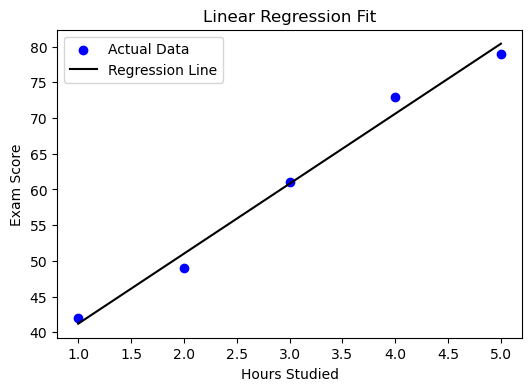

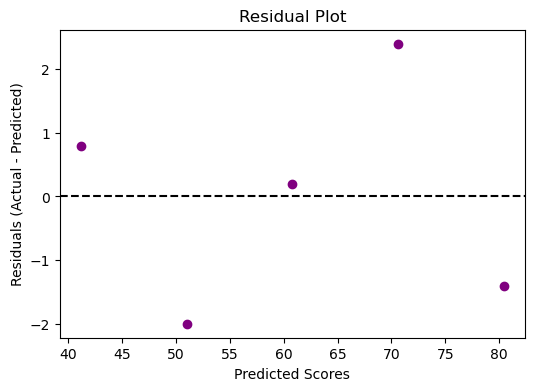

In [ ]:

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Independent variable (X): Hours studied
# Dependent variable (y): Exam scores
X = np.array([[1], [2], [3], [4], [5]])
y = np.array([42, 49, 61, 73, 79])

# Optional: Create a DataFrame for better readability
df = pd.DataFrame({'Hours': X.flatten(), 'Score': y})
print("Dataset:")
print(df)


model = LinearRegression()
model.fit(X, y)

# Y= β₀ + β₁ X+ ε

y_pred = model.predict(X)

print("\nModel Coefficients:")
print(f"Intercept (b0): {model.intercept_:.3f}")
print(f"Slope (b1): {model.coef_[0]:.3f}")


mae = mean_absolute_error(y, y_pred)
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)

# Adjusted R² (optional)
n = len(y)
p = X.shape[1]
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("\nEvaluation Metrics:")
print(f"MAE  = {mae:.3f}")
print(f"MSE  = {mse:.3f}")
print(f"RMSE = {rmse:.3f}")
print(f"R²   = {r2:.3f}")
print(f"Adj R² = {adj_r2:.3f}")


results = pd.DataFrame({
    "Hours": X.flatten(),
    "Actual_Score": y,
    "Predicted_Score": y_pred,
    "Residual": y - y_pred
})
print("\nPrediction Results:")
print(results)

plt.figure(figsize=(6,4))
plt.scatter(X, y, color='blue', label='Actual Data')
plt.plot(X, y_pred, color='black', label='Regression Line')
plt.title("Linear Regression Fit")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.legend()
plt.show()

#-------------------------------
plt.figure(figsize=(6,4))
plt.scatter(y_pred, y - y_pred, color='purple')
plt.axhline(0, color='black', linestyle='--')
plt.title("Residual Plot")
plt.xlabel("Predicted Scores")
plt.ylabel("Residuals (Actual - Predicted)")
plt.show()


Model coefficients:
Intercept (b0): 35.000
Slope (b1): 4.500

Training set metrics:
MAE: 0.0000 | MSE: 0.0000 | RMSE: 0.0000 | R²: 1.0000 | Adj R²: 1.0000

Test set metrics:
MAE: 0.0000 | MSE: 0.0000 | RMSE: 0.0000 | R²: 1.0000 | Adj R²: nan

Prediction results (test set):
   Hours  Actual_Score  Predicted_Score  Residual
2      3          48.5             48.5       0.0
8      9          75.5             75.5       0.0


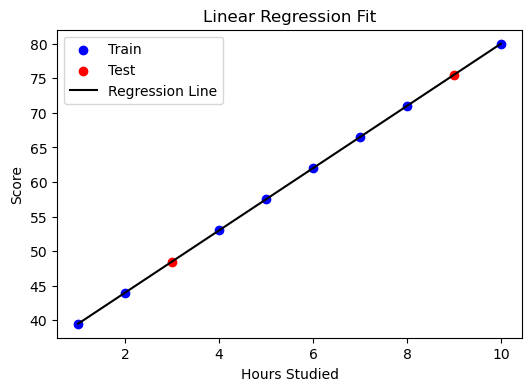

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

np.random.seed(42)
hours = np.arange(1, 11)  # study hours
scores = 35 + 4.5 * hours + np.random.randn(10) * 2  # linear relation + noise
df = pd.DataFrame({"Hours": hours, "Score": scores})

#  Hours      Score
# 0      1  40.493428
# 1      2  43.723471
# 2      3  49.795377
# 3      4  56.046060
# 4      5  57.031693
# 5      6  61.531726
# 6      7  69.658426
# 7      8  72.534869
# 8      9  74.561051
# 9     10  81.085120

# Split train/test (80/20)
X = df[["Hours"]]
y = df["Score"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

# Train model
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# Metrics function (includes adjusted R²)
def regression_metrics(y_true, y_pred, X):
    n = len(y_true)
    p = X.shape[1]
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1) if n - p - 1 > 0 else np.nan
    return mae, mse, rmse, r2, adj_r2

# Calculate metrics
train_mae, train_mse, train_rmse, train_r2, train_adj_r2 = regression_metrics(y_train, y_pred_train, X_train)
test_mae, test_mse, test_rmse, test_r2, test_adj_r2 = regression_metrics(y_test, y_pred_test, X_test)

# Results
print("Model coefficients:")
print(f"Intercept (b0): {model.intercept_:.3f}")
print(f"Slope (b1): {model.coef_[0]:.3f}")
print("\nTraining set metrics:")
print(f"MAE: {train_mae:.4f} | MSE: {train_mse:.4f} | RMSE: {train_rmse:.4f} | R²: {train_r2:.4f} | Adj R²: {train_adj_r2:.4f}")
print("\nTest set metrics:")
print(f"MAE: {test_mae:.4f} | MSE: {test_mse:.4f} | RMSE: {test_rmse:.4f} | R²: {test_r2:.4f} | Adj R²: {test_adj_r2:.4f}")

# Actual vs predicted
results = pd.DataFrame({
    "Hours": X_test.squeeze(),
    "Actual_Score": y_test,
    "Predicted_Score": y_pred_test,
    "Residual": y_test - y_pred_test
})
print("\nPrediction results (test set):")
print(results)

# Plot fit
plt.figure(figsize=(6,4))
plt.scatter(X_train, y_train, color='blue', label='Train')
plt.scatter(X_test, y_test, color='red', label='Test')
plt.plot(X, model.predict(X), color='black', label='Regression Line')
plt.title("Linear Regression Fit")
plt.xlabel("Hours Studied")
plt.ylabel("Score")
plt.legend()
plt.show()


Dataset:
   Hours_Studied  Sleep_Hours  Exam_Score
0              1          7.0   51.993428
1              2          6.5   54.223471
2              3          6.0   59.295377
3              4          5.5   64.546060
4              5          5.0   64.531693
5              6          4.5   68.031726
6              7          4.0   75.158426
7              8          3.5   77.034869

Model Coefficients:
Intercept (b0): 58.885
Slope for Hours_Studied (b): 2.916
Slope for Sleep_Hours (b): -1.458

Evaluation Metrics:
MAE  = 1.130
MSE  = 1.775
RMSE = 1.332
R²   = 0.975
Adj R² = 0.965

Prediction Results:
   Hours_Studied  Sleep_Hours  Actual_Score  Predicted_Score  Residual
0              1          7.0     51.993428        51.595234  0.398194
1              2          6.5     54.223471        55.239990 -1.016519
2              3          6.0     59.295377        58.884747  0.410630
3              4          5.5     64.546060        62.529503  2.016557
4              5          5.0     64

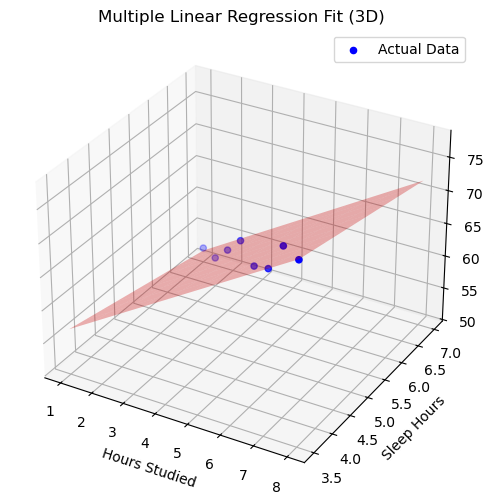

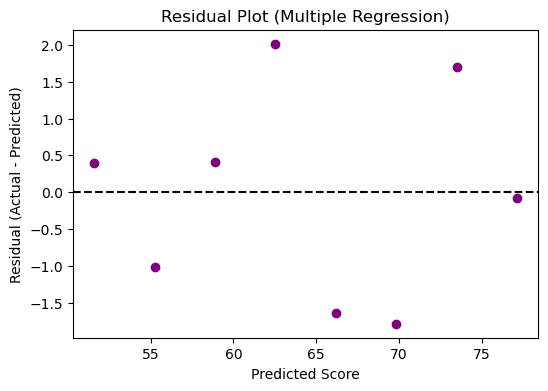

In [ ]:

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

np.random.seed(42)

# Independent variables
hours_studied = np.array([1, 2, 3, 4, 5, 6, 7, 8])
sleep_hours   = np.array([7, 6.5, 6, 5.5, 5, 4.5, 4, 3.5])

# Target variable (exam score)
exam_score = 25 + 5 * hours_studied + 3 * sleep_hours + np.random.randn(8) * 2

# Combine into DataFrame
df = pd.DataFrame({
    "Hours_Studied": hours_studied,
    "Sleep_Hours": sleep_hours,
    "Exam_Score": exam_score
})
print("Dataset:")
print(df)


X = df[["Hours_Studied", "Sleep_Hours"]]  # two features
y = df["Exam_Score"]

model = LinearRegression() 
model.fit(X, y)

y_pred = model.predict(X)


print("\nModel Coefficients:")
print(f"Intercept (b0): {model.intercept_:.3f}")
for name, coef in zip(X.columns, model.coef_):
    print(f"Slope for {name} (b): {coef:.3f}")

mae  = mean_absolute_error(y, y_pred)
mse  = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y, y_pred)

# Adjusted R²
n = len(y)
p = X.shape[1]
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("\nEvaluation Metrics:")
print(f"MAE  = {mae:.3f}")
print(f"MSE  = {mse:.3f}")
print(f"RMSE = {rmse:.3f}")
print(f"R²   = {r2:.3f}")
print(f"Adj R² = {adj_r2:.3f}")

results = pd.DataFrame({
    "Hours_Studied": X["Hours_Studied"],
    "Sleep_Hours": X["Sleep_Hours"],
    "Actual_Score": y,
    "Predicted_Score": y_pred,
    "Residual": y - y_pred
})
print("\nPrediction Results:")
print(results)

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

# Actual points
ax.scatter(df["Hours_Studied"], df["Sleep_Hours"], df["Exam_Score"], 
           color='blue', label='Actual Data')

# Predicted plane
x_surf, y_surf = np.meshgrid(
    np.linspace(df["Hours_Studied"].min(), df["Hours_Studied"].max(), 10),
    np.linspace(df["Sleep_Hours"].min(), df["Sleep_Hours"].max(), 10)
)
z_surf = (model.intercept_ 
          + model.coef_[0] * x_surf 
          + model.coef_[1] * y_surf)
ax.plot_surface(x_surf, y_surf, z_surf, alpha=0.3, color='red')

ax.set_title("Multiple Linear Regression Fit (3D)")
ax.set_xlabel("Hours Studied")
ax.set_ylabel("Sleep Hours")
ax.set_zlabel("Exam Score")
plt.legend()
plt.show()

plt.figure(figsize=(6,4))
plt.scatter(y_pred, y - y_pred, color='purple')
plt.axhline(0, color='black', linestyle='--')
plt.title("Residual Plot (Multiple Regression)")
plt.xlabel("Predicted Score")
plt.ylabel("Residual (Actual - Predicted)")
plt.show()


In [7]:
results = pd.DataFrame({
    "Hours_Studied": X["Hours_Studied"],
    "Sleep_Hours": X["Sleep_Hours"],
    "Actual_Score": y,
    "Predicted_Score": y_pred,
    "Residual": y - y_pred
})
print("\nPrediction Results:")
print(results)


Prediction Results:
   Hours_Studied  Sleep_Hours  Actual_Score  Predicted_Score  Residual
0              1          7.0     51.993428        51.595234  0.398194
1              2          6.5     54.223471        55.239990 -1.016519
2              3          6.0     59.295377        58.884747  0.410630
3              4          5.5     64.546060        62.529503  2.016557
4              5          5.0     64.531693        66.174260 -1.642566
5              6          4.5     68.031726        69.819016 -1.787290
6              7          4.0     75.158426        73.463772  1.694653
7              8          3.5     77.034869        77.108529 -0.073659
